# Mapas departamentales: lluvias y declaratorias de emergencia
Plantilla basada en la sesión 7 (Geopandas + Folium). Variables: `lluvia_total_mm`, `dias_lluvia_fuerte`, `declaratorias`, `prorrogas`.

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

## 1. Llave de unión: `ubigeo` como texto de 2 dígitos

In [2]:
# dtype=str evita que '01' se convierta en el número 1
df = pd.read_csv("datos/dataset.csv", dtype={"ubigeo": str})
df["ubigeo"] = df["ubigeo"].str.strip().str.zfill(2)

print(df.shape)
print("ubigeos únicos:", df["ubigeo"].nunique())
df.head()

(25, 9)
ubigeos únicos: 25


,ubigeo,departamento,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,01,Amazonas,Chachapoyas,-6.23169,-77.86903,414.6,3,3,1
1,02,Áncash,Huaraz,-9.52614,-77.52869,1145.8,9,6,1
2,03,Apurímac,Abancay,-13.63426,-72.88380,726.2,3,1,0
3,04,Arequipa,Arequipa,-16.39899,-71.53747,362.0,1,4,0
4,05,Ayacucho,Ayacucho,-13.16380,-74.22345,498.4,2,5,1


## 2. Cargar geometrías y unir con los datos
Se busca primero el archivo local de la sesión 7/8. Si es `distritos.geojson` (ubigeo de 6 dígitos), se agrega a nivel departamental con `dissolve` usando los 2 primeros dígitos. Si no hay archivo local, se descarga un GeoJSON departamental público.

In [3]:
RUTAS_LOCALES = [
    "distritos.geojson",
    "data/07-mapas/distritos.geojson",
    "data/07-mapas/departamentos.geojson",
    "peru_departamental_simple.geojson",
]
URL_RESPALDO = ("https://raw.githubusercontent.com/juaneladio/peru-geojson/"
                "master/peru_departamental_simple.geojson")

ruta = next((r for r in RUTAS_LOCALES if os.path.exists(r)), None)
geo = gpd.read_file(ruta if ruta else URL_RESPALDO)
print("Fuente:", ruta or URL_RESPALDO)

# Detectar la columna de código y llevarla a 2 dígitos
cols_codigo = ["UBIGEO", "ubigeo", "IDDIST", "IDDPTO", "CCDD", "FIRST_IDDP"]
col = next(c for c in cols_codigo if c in geo.columns)
geo["ubigeo"] = geo[col].astype(str).str.zfill(2).str[:2]

# Si el archivo es distrital, agregamos a departamentos
if geo["ubigeo"].duplicated().any():
    geo = geo[["ubigeo", "geometry"]].dissolve(by="ubigeo").reset_index()
else:
    geo = geo[["ubigeo", "geometry"]]

geo = geo.to_crs(epsg=4326)
print("Polígonos departamentales:", len(geo))

Fuente:

 https://raw.githubusercontent.com/juaneladio/peru-geojson/master/peru_departamental_simple.geojson
Polígonos departamentales: 25


In [4]:
# Verificar el cruce antes de unir
chequeo = geo.merge(df, on="ubigeo", how="outer", indicator=True)
print(chequeo["_merge"].value_counts())

gdf = geo.merge(df, on="ubigeo", how="left")
assert gdf["lluvia_total_mm"].notna().all(), "Hay departamentos sin dato"
gdf.head()

_merge
both          25
left_only      0
right_only     0
Name: count, dtype: int64


,ubigeo,geometry,departamento,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,01,"POLYGON ((-77.75893 -6.96451, -77.84586 -6.976...",Amazonas,Chachapoyas,-6.23169,-77.86903,414.6,3,3,1
1,02,"POLYGON ((-77.31749 -8.53015, -77.28903 -8.589...",Áncash,Huaraz,-9.52614,-77.52869,1145.8,9,6,1
2,03,"POLYGON ((-72.47177 -14.6614, -72.57725 -14.68...",Apurímac,Abancay,-13.63426,-72.88380,726.2,3,1,0
3,04,"POLYGON ((-75.07333 -15.44294, -75.04965 -15.4...",Arequipa,Arequipa,-16.39899,-71.53747,362.0,1,4,0
4,05,"POLYGON ((-74.34595 -12.17374, -74.32187 -12.2...",Ayacucho,Ayacucho,-13.16380,-74.22345,498.4,2,5,1


## 3. Mapas estáticos (Geopandas, por quintiles)

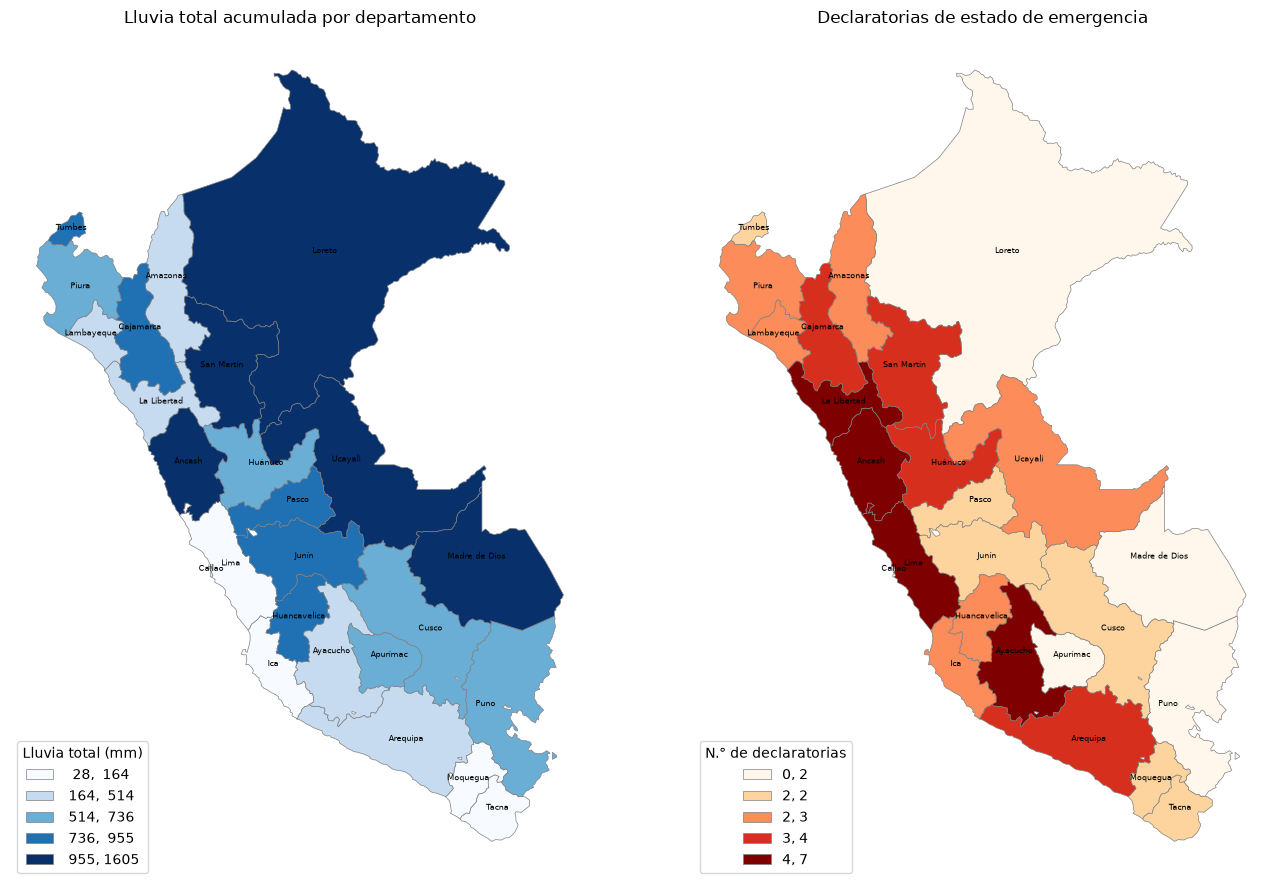

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9))

gdf.plot(column="lluvia_total_mm", cmap="Blues", scheme="quantiles", k=5, legend=True,
         edgecolor="grey", linewidth=0.5, ax=axes[0],
         legend_kwds={"title": "Lluvia total (mm)", "loc": "lower left", "fmt": "{:.0f}"})
axes[0].set_title("Lluvia total acumulada por departamento")

gdf.plot(column="declaratorias", cmap="OrRd", scheme="quantiles", k=5, legend=True,
         edgecolor="grey", linewidth=0.5, ax=axes[1],
         legend_kwds={"title": "N.° de declaratorias", "loc": "lower left", "fmt": "{:.0f}"})
axes[1].set_title("Declaratorias de estado de emergencia")

# Etiquetas con el nombre del departamento
for ax in axes:
    for _, fila in gdf.iterrows():
        p = fila.geometry.representative_point()
        ax.annotate(fila["departamento"], (p.x, p.y), fontsize=6,
                    ha="center", color="black")
    ax.axis("off")

plt.tight_layout()
plt.savefig("mapa_estatico.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Mapa interactivo (Folium) con tooltip

In [6]:
m = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles="OpenStreetMap")

folium.Choropleth(
    geo_data=gdf,
    data=df,
    columns=["ubigeo", "lluvia_total_mm"],
    key_on="feature.properties.ubigeo",
    fill_color="Blues",
    fill_opacity=0.8,
    line_opacity=0.4,
    legend_name="Lluvia total (mm)",
).add_to(m)

# Capa transparente encima para mostrar el tooltip al pasar el cursor
folium.GeoJson(
    gdf,
    style_function=lambda f: {"fillOpacity": 0, "weight": 0},
    highlight_function=lambda f: {"weight": 2, "color": "black"},
    tooltip=folium.GeoJsonTooltip(
        fields=["departamento", "lluvia_total_mm", "dias_lluvia_fuerte",
                "declaratorias", "prorrogas"],
        aliases=["Departamento:", "Lluvia total (mm):", "Días lluvia fuerte:",
                 "Declaratorias:", "Prórrogas:"],
        localize=True,
    ),
).add_to(m)

m.save("mapa_interactivo.html")
m

## 5. Patrón geográfico

In [7]:
cols = ["lluvia_total_mm", "dias_lluvia_fuerte", "declaratorias"]
print(df[cols].corr().round(2))
df.sort_values("lluvia_total_mm", ascending=False)[["departamento"] + cols].head(5)

                    lluvia_total_mm  dias_lluvia_fuerte  declaratorias
lluvia_total_mm                1.00                0.83          -0.24
dias_lluvia_fuerte             0.83                1.00          -0.30
declaratorias                 -0.24               -0.30           1.00


,departamento,lluvia_total_mm,dias_lluvia_fuerte,declaratorias
15,Loreto,1604.6,26,1
24,Ucayali,1316.0,24,3
16,Madre de Dios,1248.4,23,0
1,Áncash,1145.8,9,6
21,San Martín,1050.5,12,4


**Comentario.** La lluvia sigue un gradiente oeste–este muy marcado: la Amazonía (Loreto, Ucayali, Madre de Dios) acumula más de 1 200 mm y más de 20 días de lluvia fuerte; San Martín también supera los 1 000 mm, mientras la costa centro-sur (Tacna, Callao, Lima, Moquegua, Ica) casi no registra precipitación. En la costa norte destacan Tumbes y Piura, con valores atípicamente altos para la región. Sin embargo, el mapa de declaratorias muestra un patrón casi inverso (correlación ≈ −0.24): las emergencias se concentran en la franja costa–sierra occidental (Lima, Áncash, Ayacucho, La Libertad), no en la Amazonía, donde más llueve. Lima, con 55 mm, tiene más declaratorias (7) que Madre de Dios (0), con 1 248 mm; Áncash es la excepción, con mucha lluvia y muchas declaratorias. Esto sugiere que las declaratorias responden más a la vulnerabilidad del territorio (huaicos, quebradas, población expuesta) que al volumen de lluvia por sí solo.

**Mapa vs. gráficos.** El gráfico de dispersión de la Parte 1 ya mostraba que más lluvia no implica más declaratorias, pero no decía *dónde*. El mapa agrega la ubicación: la lluvia está en el oriente y las declaratorias en el occidente, un patrón que en los gráficos no se ve.